<center>
<h1><b> TP3: Prompt Engineering </b>
<h1><b>Classification tasks : Sentiment Analysis </b>
</center>

# Objectives

- Present LLMs as an effective tool to tackle classification problems.
- Illustrate prompt engineering for sentiment analysis.
- Build and evaluate LLMs on broader classification tasks.


# Preparer l'environement

1. Prendre VS Code, je vais créer un un nouveau dossier que je vais appeler **SMA_TokPr** et ouvrir le terminal.
2. **UV** install: utiliser la la commande, pour MacOS: ```curl -LsSf https://astral.sh/uv/install.sh | sh```  sous Windows utiliser la commande dans le powerShell: `powershell -ExecutionPolicy ByPass -c "irm https://astral.sh/uv/install.ps1 | iex"`. Après instalation de UV quittez et relancez VScode.
3. dans le terminal de VsCode utiliser la commande ` uv init ` pour initialiser le projet. Donc ça nous permet de générer la structure des projets notamment avec le fichier **.toml** .
4. créer un environnement virtuel. Avec la commande: ` uv venv ` .
3. autoriser PowerSell à exécuter les scripts avec cette commande dans le terminal: ` Set-ExecutionPolicy -ExecutionPolicy RemoteSigned -Scope Process ` . puis aller au dosssier **Scripts** et activer les scripts avec la commande:  ` .\.venv\Scripts\activate `.
5.  cree un notebook **prompttoken.ipynb** pour le test puis choisir un noyaux(le kernel) et tester avec `print("Bonjour")` .
  

7. installer la bib tiktoken avec ` uv add tiktoken `

In [1]:
import tiktoken

In [2]:
tokenizer=tiktoken.encoding_for_model("gpt-4o")


In [3]:
print(tokenizer.name)


o200k_base


In [4]:
tokenizer=tiktoken.get_encoding("o200k_base")

In [5]:
prompt="Vous êtes un expert en marketing digital. C'est quoi un digital marketer ? "

In [6]:
tokens=tokenizer.encode(prompt)

In [7]:
print(tokens)


[29038, 34077, 537, 8333, 469, 6686, 7058, 13, 363, 6616, 33399, 537, 7058, 95641, 1423, 220]


In [8]:
print(len(tokens))


16


In [9]:
for token in tokens:
    t=tokenizer.decode_single_token_bytes(token).decode("utf-8")
    print(t,end='|')

Vous| êtes| un| expert| en| marketing| digital|.| C|'est| quoi| un| digital| marketer| ?| |

# Utilisation des llm

8. installer la dépendance langchain avec la commande: ` uv add langchain ` et installer langchain-openai ` uv add langchain-openai `

In [10]:
import os

try:
    from langchain_openai import ChatOpenAI
    from dotenv import load_dotenv
except ImportError as exc:
    ChatOpenAI = None
    load_dotenv = None
    print("Dépendances LLM absentes :", exc)

aller dans openaiplatform et generer une api key puis cree un fichier .env qui contient la cle gnere

In [11]:
if load_dotenv is not None:
    load_dotenv(override=True)
    print("Fichier .env chargé si présent.")
else:
    print("python-dotenv n'est pas installé ; étape ignorée.")

Fichier .env chargé si présent.


In [12]:
llm = None
if ChatOpenAI is not None and os.getenv("OPENAI_API_KEY"):
    llm = ChatOpenAI(model="gpt-4o", temperature=0)
    print("Modèle OpenAI prêt.")
else:
    print("LLM OpenAI non initialisé : ajoutez OPENAI_API_KEY dans .env pour l'activer.")

Modèle OpenAI prêt.


**apel** a llm

In [13]:
resp = None

if llm is not None:
    try:
        resp = llm.invoke([
            {
                "role": "system",
                "content": "Vous êtes un expert en marketing digital"
            },
            {
                "role": "user",
                "content": "C'est quoi un digital marketer ?"
            }
        ])
        print(resp.content)

    except Exception as e:
        print("Erreur lors de l'appel OpenAI :")
        print(e)
else:
    print("Appel OpenAI ignoré : aucune clé API disponible.")

Erreur lors de l'appel OpenAI :
Error code: 429 - {'error': {'message': 'You have no credits remaining. Add credits to continue using the API at https://platform.openai.com/settings/organization/billing/.', 'type': 'insufficient_quota', 'param': None, 'code': 'credit_balance_exhausted'}}


In [14]:
from IPython.display import Markdown, display

In [15]:
if resp is not None:
    display(Markdown(resp.content))

# ollama llm

# dans power shell instaler ollama et utiliser la commande ` ollama run qwen3.5:cloud `

dans le terminal vscode telecharger ollama ` uv add langchain-ollama `

In [16]:
try:
    from langchain_ollama import ChatOllama
except ImportError as exc:
    ChatOllama = None
    print("langchain-ollama absent :", exc)

In [24]:
RUN_OLLAMA_DEMO = True
llm2 = None
if ChatOllama is not None and RUN_OLLAMA_DEMO:
    llm2 = ChatOllama(
        model="gemma4:31b-cloud",
        temperature=0,
        base_url="http://127.0.0.1:11434",
    )
    print("Client Ollama prêt. Le serveur sera contacté au moment de l'appel.")
else:
    print("Démo Ollama désactivée. Passez RUN_OLLAMA_DEMO à True pour l'activer.")


Client Ollama prêt. Le serveur sera contacté au moment de l'appel.


In [25]:
resp2 = None

try:
    if llm2 is None:
        raise RuntimeError("Ollama model is not initialized.")
    resp2 = llm2.invoke([
        {"role": "system", "content": "Vous êtes un expert en marketing digital"},
        {"role": "user", "content": "C'est quoi un digital marketer ?"}
    ])
    print(resp2.content)
except Exception as e:
    print("Échec de l'appel Ollama. Pour un modèle cloud, vérifiez votre connexion Ollama.")
    print(e)

print(resp2.content)

En tant qu'expert, je vais vous répondre de manière précise. Pour faire simple : **un digital marketer (ou responsable marketing numérique) est le chef d'orchestre de la visibilité d'une marque sur Internet.**

Si le marketing traditionnel utilise des panneaux publicitaires, la radio ou la presse, le digital marketer utilise tous les leviers numériques pour **attirer l'attention, convertir des prospects en clients et fidéliser ces derniers.**

Voici le détail de ce qu'est réellement ce métier aujourd'hui :

### 1. Ses objectifs principaux
Le digital marketer ne se contente pas de "poster sur Facebook". Ses objectifs sont chiffrés (KPIs) :
*   **Générer du trafic :** Faire venir le maximum de personnes qualifiées sur un site web ou une application.
*   **Générer des leads :** Récupérer des contacts (emails, numéros de téléphone).
*   **Augmenter les ventes :** Transformer un visiteur anonyme en acheteur.
*   **Améliorer la notoriété :** Faire en sorte que la marque soit reconnue et aimé

In [26]:
if resp2 is not None:
    display(Markdown(resp2.content))

En tant qu'expert, je vais vous répondre de manière précise. Pour faire simple : **un digital marketer (ou responsable marketing numérique) est le chef d'orchestre de la visibilité d'une marque sur Internet.**

Si le marketing traditionnel utilise des panneaux publicitaires, la radio ou la presse, le digital marketer utilise tous les leviers numériques pour **attirer l'attention, convertir des prospects en clients et fidéliser ces derniers.**

Voici le détail de ce qu'est réellement ce métier aujourd'hui :

### 1. Ses objectifs principaux
Le digital marketer ne se contente pas de "poster sur Facebook". Ses objectifs sont chiffrés (KPIs) :
*   **Générer du trafic :** Faire venir le maximum de personnes qualifiées sur un site web ou une application.
*   **Générer des leads :** Récupérer des contacts (emails, numéros de téléphone).
*   **Augmenter les ventes :** Transformer un visiteur anonyme en acheteur.
*   **Améliorer la notoriété :** Faire en sorte que la marque soit reconnue et aimée.

### 2. Sa "boîte à outils" (Les leviers)
Un digital marketer peut être généraliste (T-shaped marketer) ou spécialiste. Il jongle avec plusieurs canaux :

*   **Le SEO (Search Engine Optimization) :** L'art d'optimiser un site pour qu'il apparaisse en premier sur Google gratuitement.
*   **Le SEA (Search Engine Advertising) :** La publicité payante sur les moteurs de recherche (Google Ads).
*   **Le Social Media Marketing (SMM) :** La gestion des réseaux sociaux (Instagram, TikTok, LinkedIn, etc.) pour créer une communauté.
*   **Le Content Marketing :** La création de contenus à forte valeur ajoutée (articles de blog, vidéos, livres blancs) pour attirer et éduquer le client.
*   **L'Emailing & Automation :** L'envoi de campagnes ciblées et la mise en place de scénarios automatiques (ex: email de bienvenue après une inscription).
*   **L'Analyse de données (Data Analytics) :** L'utilisation d'outils comme Google Analytics pour mesurer ce qui fonctionne et ce qui échoue.

### 3. La différence fondamentale avec le marketing classique
La grande force du digital marketer, c'est la **mesurabilité**. 
Dans une publicité papier, on ne sait jamais exactement combien de personnes ont acheté le produit grâce à cette page précise. En digital, on sait tout :
*   Combien de personnes ont cliqué.
*   D'où elles viennent (ville, appareil, réseau social).
*   Combien de centimes chaque vente a coûté en publicité.

### 4. Le profil type
C'est un métier hybride qui demande :
*   **Un esprit analytique :** Aimer les chiffres et les tests (A/B testing).
*   **Une fibre créative :** Savoir écrire des textes accrocheurs (Copywriting) et comprendre le visuel.
*   **Une curiosité insatiable :** Les algorithmes de Google et Meta changent toutes les semaines ; il faut apprendre en permanence.

**En résumé :** Le digital marketer est le pont entre un produit et son client idéal, en utilisant la technologie pour rendre ce lien le plus efficace et rentable possible.

# TP3 — Analyse de sentiment sur le jeu de données IMDB

Cette section applique la démarche du chapitre de prompt engineering au fichier IMDB Dataset.csv :

1. définir l'objectif et les métriques ;
2. préparer les avis et leurs étiquettes ;
3. construire des prompts zero-shot, few-shot et Chain-of-Thought ;
4. évaluer les prompts sur des exemples de référence (gold examples).

Les appels à un LLM sont désactivés par défaut pour éviter une consommation involontaire de crédits. Ils peuvent être activés dans la dernière partie après configuration d'OpenAI ou d'Ollama.

In [37]:
# Imports et paramètres généraux
from pathlib import Path
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

RANDOM_STATE = 42
N_FEW_SHOT_PER_CLASS = 4
N_GOLD_EXAMPLES = 200
N_EVAL_RUNS = 10
RUN_LLM_EVALUATION = False

print("Paramètres chargés.")

Paramètres chargés.


## Étape 1 — Objectif et métriques

Le modèle doit attribuer à chaque avis l'une des deux classes positive ou negative. Les résultats seront comparés aux étiquettes de référence avec l'accuracy et le micro-F1.

Dans une classification binaire à une seule étiquette, le micro-F1 est numériquement égal à l'accuracy lorsque toutes les prédictions sont valides. Nous conservons néanmoins le micro-F1, car il correspond à la métrique demandée dans le chapitre.

In [38]:
# Localisation robuste du fichier lorsque le notebook est lancé depuis VS Code
candidates = [
    Path("IMDB Dataset.csv"),
    Path.cwd() / "IMDB Dataset.csv",
    Path.cwd() / "TP3" / "IMDB Dataset.csv",
]
DATA_PATH = next((path for path in candidates if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "IMDB Dataset.csv est introuvable. Placez-le dans le dossier du notebook."
    )

df = pd.read_csv(DATA_PATH)
expected_columns = {"review", "sentiment"}
if not expected_columns.issubset(df.columns):
    raise ValueError(
        f"Colonnes attendues : {expected_columns}. Colonnes trouvées : {list(df.columns)}"
    )

df = df[["review", "sentiment"]].rename(columns={"review": "text"})
df["sentiment"] = df["sentiment"].astype(str).str.strip().str.lower()
df = df.dropna(subset=["text", "sentiment"]).reset_index(drop=True)

valid_labels = {"positive", "negative"}
if not set(df["sentiment"].unique()).issubset(valid_labels):
    raise ValueError(f"Étiquettes inattendues : {sorted(set(df['sentiment']))}")

print(f"Fichier utilisé : {DATA_PATH.resolve()}")
print(f"Nombre d'avis : {len(df):,}")
print("Répartition des classes :")
display(df["sentiment"].value_counts().rename_axis("sentiment").to_frame("count"))
display(df.head(3))

Fichier utilisé : C:\Users\Lenovo\Desktop\Distributed-Agentic-System\TP3\IMDB Dataset.csv
Nombre d'avis : 50,000
Répartition des classes :


,count
sentiment,
positive,25000
negative,25000


,text,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive


Valeurs manquantes :


text         0
sentiment    0
Name: missing, dtype: int64

Doublons exacts : 418


,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,25000.0,1294.1,945.9,32.0,706.0,973.0,1567.2,8969.0
positive,25000.0,1324.8,1031.5,65.0,691.0,968.0,1614.0,13704.0


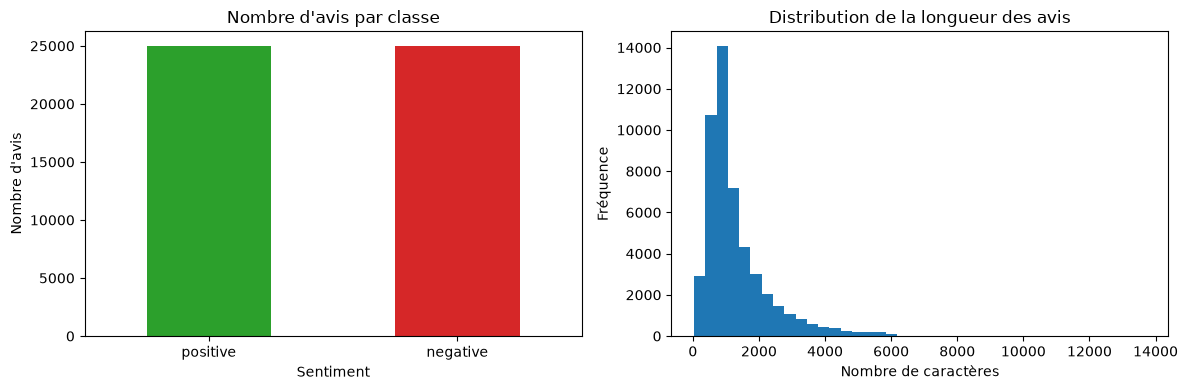

In [39]:
# Contrôle de la qualité et visualisation de la distribution
print("Valeurs manquantes :")
display(df.isna().sum().rename("missing"))
print(f"Doublons exacts : {df.duplicated().sum():,}")

df["text_length"] = df["text"].str.len()
display(df.groupby("sentiment")["text_length"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["sentiment"].value_counts().reindex(["positive", "negative"]).plot(
    kind="bar", ax=axes[0], color=["#2ca02c", "#d62728"],
    title="Nombre d'avis par classe"
)
axes[0].set_xlabel("Sentiment")
axes[0].set_ylabel("Nombre d'avis")
axes[0].tick_params(axis="x", rotation=0)

df["text_length"].plot(kind="hist", bins=40, ax=axes[1], color="#1f77b4")
axes[1].set_title("Distribution de la longueur des avis")
axes[1].set_xlabel("Nombre de caractères")
axes[1].set_ylabel("Fréquence")
fig.tight_layout()
plt.show()

## Étape 2 — Séparer les exemples et les données de référence

Les few-shot examples servent à montrer au modèle comment répondre. Les gold examples ne sont pas placés dans le prompt : ils servent à mesurer la qualité de la prédiction.

La séparation est stratifiée afin de conserver des proportions proches de 50 % de positifs et 50 % de négatifs dans les deux parties.

In [40]:
# La colonne text_length sert uniquement à l'exploration et ne doit pas entrer dans le prompt.
df_model = df[["text", "sentiment"]].copy()

examples_df, gold_examples_df = train_test_split(
    df_model,
    test_size=N_GOLD_EXAMPLES,
    random_state=RANDOM_STATE,
    stratify=df_model["sentiment"],
)

examples_df = examples_df.reset_index(drop=True)
gold_examples_df = gold_examples_df.reset_index(drop=True)

print(f"Réservoir d'exemples : {len(examples_df)} avis")
print(f"Jeu gold : {len(gold_examples_df)} avis")
print("Répartition du jeu gold :")
display(gold_examples_df["sentiment"].value_counts())

Réservoir d'exemples : 49800 avis
Jeu gold : 200 avis
Répartition du jeu gold :


sentiment
positive    100
negative    100
Name: count, dtype: int64

## Étape 3 — Construire les prompts

Le modèle doit toujours recevoir une consigne de sortie stricte : répondre uniquement positive ou negative. Les avis sont entourés par des triples backticks afin de distinguer les données de l'instruction.

In [41]:
user_message_template = """Classify the sentiment of this movie review.
Reply with exactly one label: positive or negative.

Review:
<REVIEW>{movie_review}</REVIEW>"""

zero_shot_system_message = """You classify movie reviews.
Return exactly one label: positive or negative.
Do not explain your answer."""

few_shot_system_message = """You classify movie reviews as positive or negative.
Movie reviews are delimited by review tags.
Return exactly one label: positive or negative.
Do not explain your answer."""

cot_system_message = """You classify movie reviews as positive or negative.
Movie reviews are delimited by review tags.
Before answering, carefully consider the overall sentiment, including praise,
criticism and the final opinion. Then return exactly one label: positive or negative.
Do not expose your reasoning and do not explain your answer."""


def create_examples(dataset, n=N_FEW_SHOT_PER_CLASS, random_state=None):
    """Sélectionne n exemples de chaque classe puis les mélange."""
    if n <= 0:
        raise ValueError("n doit être strictement positif")

    positive = dataset[dataset["sentiment"] == "positive"]
    negative = dataset[dataset["sentiment"] == "negative"]
    if len(positive) < n or len(negative) < n:
        raise ValueError("Le dataset ne contient pas assez d'exemples dans une classe.")

    selected = pd.concat([
        positive.sample(n=n, random_state=random_state),
        negative.sample(
            n=n,
            random_state=None if random_state is None else random_state + 1,
        ),
    ])
    selected = selected.sample(
        frac=1,
        random_state=None if random_state is None else random_state + 2,
    )
    return selected[["text", "sentiment"]].to_json(
        orient="records", force_ascii=False
    )


def create_prompt(system_message, examples_json=None):
    """Construit un prompt de type chat avec ou sans exemples."""
    prompt = [{"role": "system", "content": system_message}]
    if examples_json is not None:
        for example in json.loads(examples_json):
            prompt.append({
                "role": "user",
                "content": user_message_template.format(movie_review=example["text"]),
            })
            prompt.append({
                "role": "assistant",
                "content": example["sentiment"],
            })
    return prompt


examples_json = create_examples(
    examples_df,
    n=N_FEW_SHOT_PER_CLASS,
    random_state=RANDOM_STATE,
)
zero_shot_prompt = create_prompt(zero_shot_system_message)
few_shot_prompt = create_prompt(few_shot_system_message, examples_json)
cot_few_shot_prompt = create_prompt(cot_system_message, examples_json)

print(f"Nombre de messages zero-shot : {len(zero_shot_prompt)}")
print(f"Nombre de messages few-shot : {len(few_shot_prompt)}")
print("Exemple de prompt few-shot :")
print(json.dumps(few_shot_prompt[:3], ensure_ascii=False, indent=2)[:3500])

Nombre de messages zero-shot : 1
Nombre de messages few-shot : 17
Exemple de prompt few-shot :
[
  {
    "role": "system",
    "content": "You classify movie reviews as positive or negative.\nMovie reviews are delimited by review tags.\nReturn exactly one label: positive or negative.\nDo not explain your answer."
  },
  {
    "role": "user",
    "content": "Classify the sentiment of this movie review.\nReply with exactly one label: positive or negative.\n\nReview:\n<REVIEW>It is obviously illegal. Pedophiles pray on stuff like this. How did they get away with making such a movie? This movie is all summed up in one word, SICK. Where do people get off making, and watching these kinds of films. As I was watching the movie I didn't actually think they would allow this kid that is say maybe 12 if that actually sleep with this woman. Sorry if this is a spoiler to you but I would have rater not seen this. Where has the sanity of these people gone? Maybe the makers of this movie are pedophiles

### Pourquoi équilibrer et mélanger les exemples ?

Si le prompt contient presque uniquement des avis positifs, le modèle peut développer un biais vers positive. Un ordre fixe peut également créer un biais de récence. La fonction précédente sélectionne donc le même nombre d'avis par classe, puis mélange leur ordre.

## Étape 4 — Évaluer les prompts

La fonction suivante normalise la réponse du LLM. Une réponse différente de positive ou negative est marquée unknown afin de ne pas être considérée comme une réponse correcte.

In [42]:
def normalize_prediction(response_content):
    """Accepte uniquement une réponse correspondant exactement à une classe."""
    if hasattr(response_content, "content"):
        response_content = response_content.content
    answer = str(response_content).strip().lower()
    if answer in {"positive", "negative"}:
        return answer
    return "unknown"


def evaluate_prompt(prompt, gold_df, model, show_progress=False):
    """Évalue un prompt sur le même jeu gold et renvoie les métriques."""
    if model is None:
        raise ValueError("Aucun modèle n'est disponible pour l'évaluation.")

    predictions = []
    truths = gold_df["sentiment"].tolist()
    iterator = gold_df.itertuples(index=False)
    if show_progress:
        iterator = tqdm(iterator, total=len(gold_df), desc="Évaluation")

    errors = 0
    for row in iterator:
        user_message = [{
            "role": "user",
            "content": user_message_template.format(movie_review=row.text),
        }]
        try:
            response = model.invoke(prompt + user_message)
            predictions.append(normalize_prediction(response))
        except Exception as exc:
            errors += 1
            predictions.append("unknown")
            if errors <= 3:
                print("Erreur pendant un appel :", exc)

    labels = ["negative", "positive"]
    if "unknown" in predictions:
        labels.append("unknown")

    return {
        "accuracy": accuracy_score(truths, predictions),
        "micro_f1": f1_score(
            truths, predictions, labels=labels, average="micro", zero_division=0
        ),
        "predictions": predictions,
        "errors": errors,
        "report": classification_report(
            truths, predictions, labels=labels, zero_division=0
        ),
    }

## Évaluation facultative avec OpenAI ou Ollama

Pour éviter de lancer des appels payants automatiquement, RUN_LLM_EVALUATION vaut False. Après avoir configuré .env avec OPENAI_API_KEY, mettez cette variable à True et relancez les cellules de cette section.

Pour une première vérification, le jeu gold contient 40 avis et trois tirages d'exemples sont évalués. Pour le rendu final, vous pouvez augmenter N_EVAL_RUNS après avoir vérifié le coût et la disponibilité du modèle.

In [43]:
# Activer l'évaluation
RUN_LLM_EVALUATION = True

# Utiliser Ollama en priorité
if "llm2" in globals() and llm2 is not None:
    active_model = llm2
    print("Modèle utilisé : Ollama")
elif "llm" in globals() and llm is not None:
    active_model = llm
    print("Modèle utilisé : OpenAI")
else:
    active_model = None
    print("Aucun modèle disponible.")

if RUN_LLM_EVALUATION and active_model is not None:
    single_run_results = {}

    for name, prompt in {
        "zero_shot": zero_shot_prompt,
        "few_shot": few_shot_prompt,
        "cot_few_shot": cot_few_shot_prompt,
    }.items():

        result = evaluate_prompt(
            prompt,
            gold_examples_df,
            active_model,
            show_progress=True,
        )

        single_run_results[name] = result

        print(
            f"{name}: "
            f"accuracy={result['accuracy']:.3f}, "
            f"micro-F1={result['micro_f1']:.3f}"
        )
else:
    print("Évaluation impossible : aucun modèle disponible.")

Modèle utilisé : Ollama


Évaluation: 100%|██████████| 200/200 [01:45<00:00,  1.90it/s]


zero_shot: accuracy=0.970, micro-F1=0.970


Évaluation: 100%|██████████| 200/200 [01:52<00:00,  1.78it/s]


few_shot: accuracy=0.960, micro-F1=0.960


Évaluation: 100%|██████████| 200/200 [01:40<00:00,  1.98it/s]

cot_few_shot: accuracy=0.965, micro-F1=0.965


In [44]:
# Vérification des prédictions produites par chaque prompt
if "single_run_results" in globals():
    for nom, resultat in single_run_results.items():
        print(f"\n{nom}")
        print(resultat["predictions"])
else:
    print("Exécutez d'abord le bloc d'évaluation des trois prompts.")


zero_shot
['positive', 'negative', 'positive', 'negative', 'negative', 'negative', 'positive', 'negative', 'positive', 'negative', 'negative', 'positive', 'negative', 'positive', 'negative', 'positive', 'negative', 'negative', 'negative', 'negative', 'positive', 'negative', 'positive', 'negative', 'positive', 'positive', 'negative', 'positive', 'negative', 'positive', 'negative', 'positive', 'positive', 'positive', 'negative', 'positive', 'positive', 'positive', 'positive', 'negative', 'negative', 'positive', 'positive', 'negative', 'negative', 'positive', 'positive', 'positive', 'positive', 'negative', 'positive', 'negative', 'positive', 'positive', 'negative', 'positive', 'negative', 'positive', 'negative', 'negative', 'positive', 'positive', 'negative', 'negative', 'positive', 'negative', 'positive', 'negative', 'positive', 'positive', 'negative', 'negative', 'positive', 'positive', 'negative', 'negative', 'negative', 'negative', 'positive', 'negative', 'positive', 'positive', 'neg

In [45]:
# Évaluation répétée avec Ollama
RUN_LLM_EVALUATION = True
active_model = llm2
N_EVAL_RUNS = 3

if active_model is not None:
    few_shot_scores = []
    cot_scores = []

    for run in tqdm(
        range(N_EVAL_RUNS),
        desc="Tirages few-shot"
    ):
        run_examples = create_examples(
            examples_df,
            n=N_FEW_SHOT_PER_CLASS,
            random_state=RANDOM_STATE + run,
        )

        run_few_prompt = create_prompt(
            few_shot_system_message,
            run_examples
        )

        run_cot_prompt = create_prompt(
            cot_system_message,
            run_examples
        )

        few_result = evaluate_prompt(
            run_few_prompt,
            gold_examples_df,
            active_model,
        )

        cot_result = evaluate_prompt(
            run_cot_prompt,
            gold_examples_df,
            active_model,
        )

        few_shot_scores.append(
            few_result["micro_f1"]
        )

        cot_scores.append(
            cot_result["micro_f1"]
        )

    summary = pd.DataFrame({
        "prompt": ["few_shot", "cot_few_shot"],
        "mean_micro_f1": [
            np.mean(few_shot_scores),
            np.mean(cot_scores),
        ],
        "std_micro_f1": [
            np.std(few_shot_scores),
            np.std(cot_scores),
        ],
    })

    display(summary.round(3))

else:
    print("Aucun modèle Ollama disponible.")

Tirages few-shot: 100%|██████████| 3/3 [11:31<00:00, 230.61s/it]


,prompt,mean_micro_f1,std_micro_f1
0,few_shot,0.963,0.002
1,cot_few_shot,0.965,0.000


In [46]:
# Scores obtenus à chaque répétition
if "few_shot_scores" in globals() and "cot_scores" in globals():
    print("Few-shot :", few_shot_scores)
    print("CoT few-shot :", cot_scores)
else:
    print("Exécutez d'abord le bloc d'évaluation répétée.")

Few-shot : [0.96, 0.965, 0.965]
CoT few-shot : [0.965, 0.965, 0.965]


## Analyse et interprétation des résultats obtenus

L'évaluation répétée a été réalisée avec Ollama sur un jeu de 200 gold examples.
Les scores observés pour les trois tirages sont :

```text
Few-shot : [0.960, 0.965, 0.965]
CoT few-shot : [0.965, 0.965, 0.965]
```

| Prompt | Micro-F1 moyen | Écart-type |
|---|---:|---:|
| Few-shot | 0,963 | 0,002 |
| CoT few-shot | 0,965 | 0,000 |

### Interprétation

Le prompt CoT few-shot obtient un score moyen légèrement supérieur au prompt few-shot : 0,965 contre 0,963. La différence est de 0,002, soit 0,2 point de pourcentage ; elle reste faible et ne permet pas d'affirmer que le CoT est systématiquement supérieur.

Le prompt few-shot varie légèrement selon les exemples sélectionnés : son écart-type est de 0,002. Le prompt CoT few-shot obtient le même score lors des trois tirages, ce qui indique une stabilité parfaite dans cette expérience limitée.

L'utilisation de 200 gold examples donne une estimation plus fine que l'évaluation précédente sur 40 exemples. Avec 200 exemples, une erreur modifie le score de 0,005, alors qu'elle le modifiait de 0,025 avec 40 exemples. Le score moyen est donc plus informatif et moins sensible à une seule prédiction.

### Comparaison avec l'évaluation précédente

Lors de la première évaluation, les trois prompts avaient obtenu 0,975 sur 40 exemples. Les nouveaux scores légèrement inférieurs ne signifient pas nécessairement que les prompts sont moins bons : le jeu de référence est plus grand et contient probablement des avis plus variés ou plus difficiles. Cette nouvelle mesure est donc plus représentative.

### Attention sur le nombre de répétitions

La barre d'exécution affiche `3/3` : les résultats présentés correspondent donc à trois répétitions. Même si la variable du notebook a été préparée avec `N_EVAL_RUNS = 10`, cette valeur n'a pas encore été appliquée au kernel lors de cette exécution. Pour obtenir dix tirages, il faut relancer la cellule des paramètres, puis les cellules de séparation et d'évaluation.

### Conclusion

Dans les conditions observées, le CoT few-shot présente un très léger avantage et une meilleure stabilité que le few-shot. Cependant, l'écart de 0,002 est faible. La conclusion raisonnable est que les deux prompts sont très performants, tandis que le CoT n'apporte qu'un gain marginal sur ce modèle et ce jeu de données.

Pour une conclusion finale plus robuste, il est conseillé d'exécuter réellement `N_EVAL_RUNS = 10` et de comparer les dix scores de chaque stratégie.

## Conclusion

Cette expérimentation compare trois stratégies :

- zero-shot : aucune démonstration ;
- few-shot : exemples positifs et négatifs équilibrés ;
- CoT few-shot : mêmes exemples, avec des instructions d'analyse plus détaillées.

Le choix final doit tenir compte de la moyenne du micro-F1, de son écart-type, du respect du format de sortie et du coût des appels. Un score parfait obtenu sur une seule petite sélection de gold examples ne suffit pas à prouver qu'un prompt est supérieur : il faut répéter l'évaluation avec un jeu de référence fixe et plusieurs tirages d'exemples.